## Pairwise Correlation Analysis of Housing Indicators Across Catalan Municipalities (2025)

* **Author:** Adrià Benito Carayol
* **Project:** `Speculation-Map` — Big Data Analysis and Visualization (University of Barcelona)


This notebook explores pairwise relationships across all Catalan municipalities using **2025** records for average rent prices, tourist-use dwellings, vacant dwellings (IHB), and municipal population, combined with the **2021** housing census for total dwelling stock normalized by 2021 population. Zero or missing records are excluded and logarithmic scales are applied where appropriate:

* **Top row (A–C):** Average monthly rent (€/month, 2025) vs. total dwellings per capita (2021), tourist dwellings per capita (2025), and vacant dwellings per capita (2025).
* **Bottom row (D–F):** Pairwise *log-log* comparisons between total housing stock (2021), tourist accommodation density (2025), and vacant housing rates (2025).

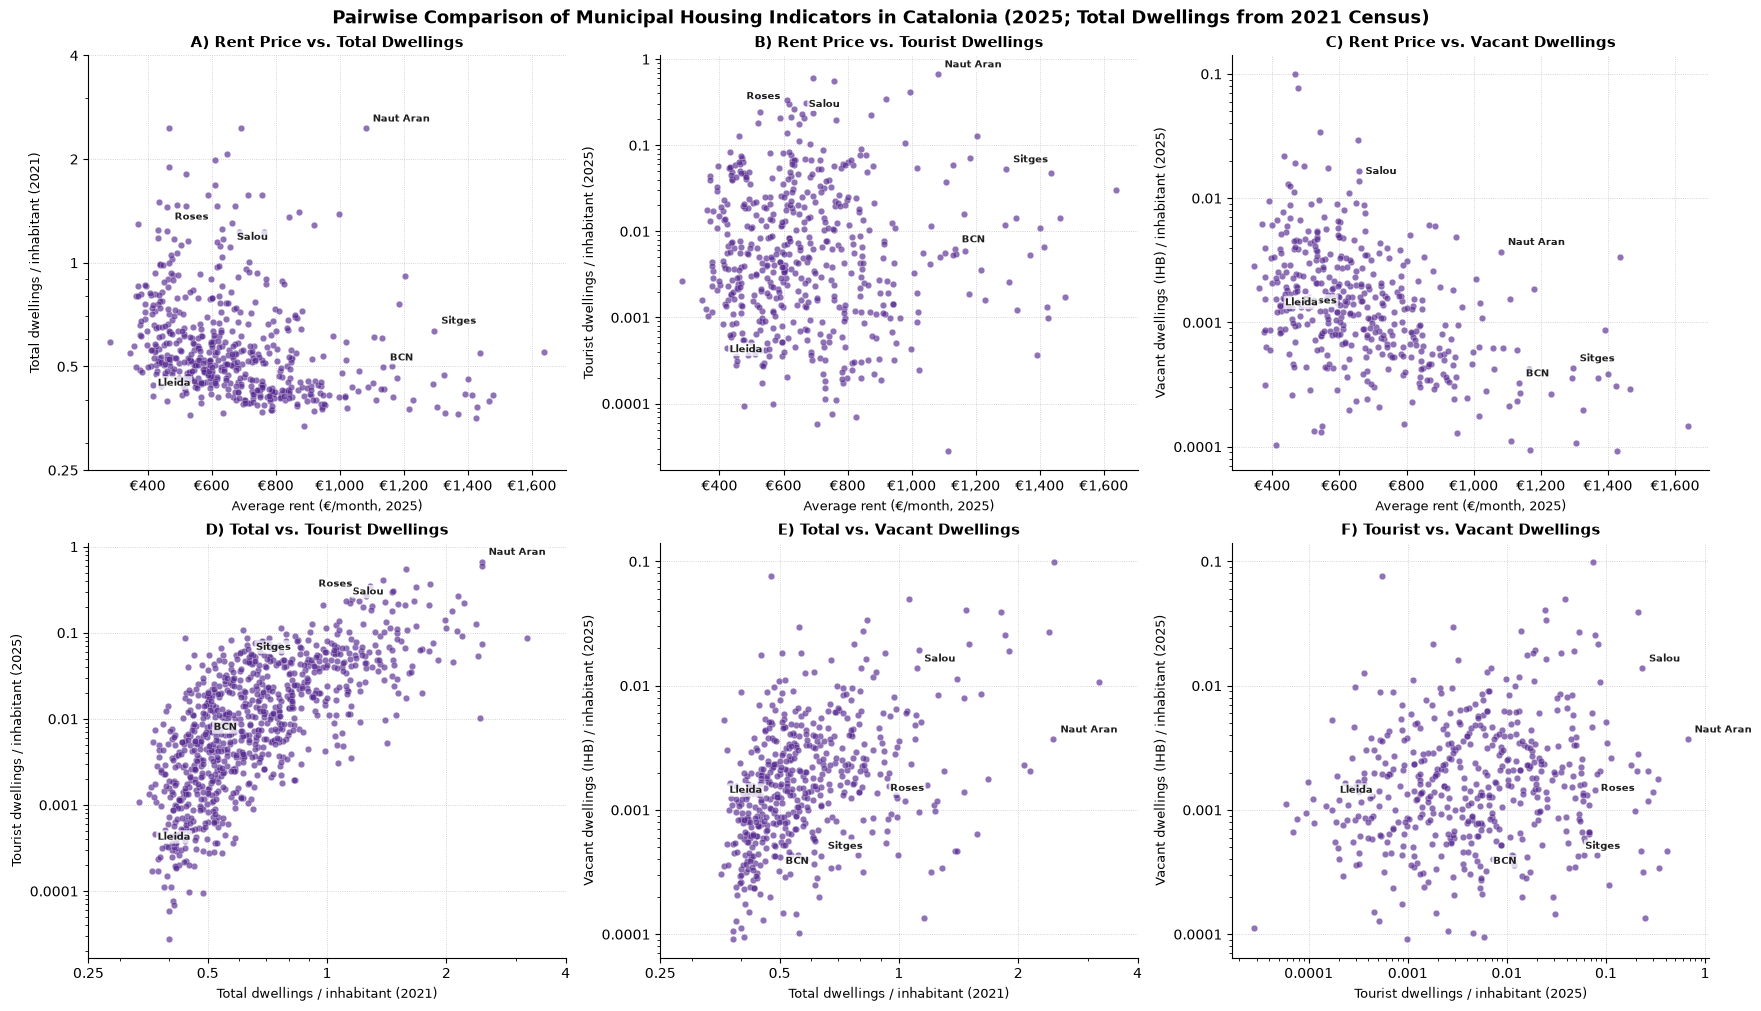

In [13]:
# Pairwise exploration (6 subplots): excluding zero values with logarithmic scales (2025; 2021 for total dwellings)

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

# 1. GEOGRAPHIC LAYER, POPULATION (2021 & 2025), AND TOTAL DWELLINGS (2021 CENSUS)
municipis = gpd.read_file("../Data/CatalunyaMapMunicipalities.json")  # Load municipal geographic layer of Catalonia
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convert municipal code to 6-digit zero-padded string

# 1A. Population 2021 
ruta_pob_2021 = "../Data/BuildingsAvailable/poblacio_codis.xlsx"
df_pob_hist = pd.read_excel(ruta_pob_2021, sheet_name="Dades", skiprows=1, dtype={0: str})
df_pob_hist = df_pob_hist.rename(columns={df_pob_hist.columns[0]: "Codi", df_pob_hist.columns[1]: "Any"})
df_pob_hist["Codi"] = df_pob_hist["Codi"].ffill().str.strip().str.zfill(6)
df_pob_hist = df_pob_hist[df_pob_hist["Codi"].str.match(r"^\d{6}$")].copy()
df_pob_hist["Any"] = df_pob_hist["Any"].astype(int)
df_pob_hist["Poblacio_2021"] = pd.to_numeric(df_pob_hist["Total"], errors="coerce")
pob_2021 = df_pob_hist[df_pob_hist["Any"] == 2021][["Codi", "Poblacio_2021"]]

# 1B. Population 2025 
ruta_pob_2025 = "../Data/Habitants.csv"
df_pob_2025 = pd.read_csv(ruta_pob_2025, dtype=str)
df_pob_2025 = df_pob_2025[(df_pob_2025["YEAR"] == "2025") & (df_pob_2025["SEX"] == "TOTAL")].copy()
df_pob_2025["Codi"] = df_pob_2025["MUN"].str.strip().str.zfill(6)
df_pob_2025["Poblacio_2025"] = pd.to_numeric(df_pob_2025["value"], errors="coerce")
pob_2025 = df_pob_2025[["Codi", "Poblacio_2025"]]

# 1C. Total family dwellings 
ruta_hab = "../Data/BuildingsAvailable/habitatges2021.csv"
df_hab = pd.read_csv(ruta_hab, sep=";", skiprows=5, dtype={"Codi": str})
df_hab = df_hab.dropna(subset=["Codi"]).copy()
df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)
df_hab["Total"] = pd.to_numeric(df_hab["Total habitatges familiars"], errors="coerce")

# 2. RENT PRICE, TOURIST DWELLINGS, AND VACANT DWELLINGS (2025)
# 2A. Average monthly rent 
ruta_lloguer = "../Data/RentPrice/RentPrice.csv"
df_lloguer = pd.read_csv(ruta_lloguer, sep=";", dtype=str)
df_lloguer = df_lloguer[
    (df_lloguer["Àmbit territorial"] == "Municipi")
    & (df_lloguer["Any"] == "2025")
].copy()
if "gener-desembre" in df_lloguer["Període"].values:
    df_lloguer = df_lloguer[df_lloguer["Període"] == "gener-desembre"].copy()

df_lloguer["Codi5"] = df_lloguer["Codi territorial"].str.strip().str.zfill(5)
df_lloguer["Lloguer"] = pd.to_numeric(
    df_lloguer["Renda"].str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
    errors="coerce",
)
df_lloguer_2025 = df_lloguer.groupby("Codi5", as_index=False)["Lloguer"].mean()

# 2B. Tourist-use dwellings 
ruta_tur = "../Data/TouristicRentals/prova2025.csv"
df_tur = pd.read_csv(ruta_tur, dtype=str)
df_hut = df_tur[df_tur["tipus_establiment"] == "Habitatges d'ús turístic"].copy()
df_hut["Codi"] = df_hut["codi_municipi_idescat"].str.strip().str.zfill(6)
tur_per_muni = df_hut.groupby("Codi").size().reset_index(name="Num_turistics")

# 2C. Vacant dwellings 
ruta_buits = "../Data/EmptyBuildings/EmptyBuildings.csv"
df_ihb = pd.read_csv(ruta_buits, dtype=str)
df_ihb_2025 = df_ihb[df_ihb["Any"] == "2025"].copy()
df_ihb_2025["Codi"] = df_ihb_2025["Codi"].str.strip().str.zfill(6)
df_ihb_2025["Habitatges"] = pd.to_numeric(df_ihb_2025["Habitatges"].str.replace(".", "", regex=False), errors="coerce")
buits_per_muni = df_ihb_2025.groupby("Codi")["Habitatges"].sum().reset_index(name="Num_buits")

# 3. MERGE ALL VARIABLES AND NORMALIZE PER INHABITANT (WITHOUT ZERO-FILLING)
df_base = (
    df_hab[["Codi", "Total"]]
    .merge(pob_2021, on="Codi", how="inner")
    .merge(pob_2025, on="Codi", how="inner")
    .merge(municipis[["CODIMUNI", "NOMMUNI"]], left_on="Codi", right_on="CODIMUNI", how="inner")
    .merge(tur_per_muni, on="Codi", how="left")
    .merge(buits_per_muni, on="Codi", how="left")
)
df_base = df_base.dropna(subset=["Total", "Poblacio_2021", "Poblacio_2025"]).copy()
df_base = df_base[(df_base["Poblacio_2021"] > 0) & (df_base["Poblacio_2025"] > 0) & (df_base["Total"] > 0)].copy()

# Compute per-capita ratios (2021 dwellings / 2021 pop; 2025 tourist & vacant dwellings / 2025 pop)
df_base["Hab_per_hab"] = df_base["Total"] / df_base["Poblacio_2021"]
df_base["Tur_per_hab"] = df_base["Num_turistics"] / df_base["Poblacio_2025"]
df_base["Buits_per_hab"] = df_base["Num_buits"] / df_base["Poblacio_2025"]

# Merge 2025 average rent price
df_base["Codi5"] = df_base["Codi"].str[:5]
df = df_base.merge(df_lloguer_2025[["Codi5", "Lloguer"]], on="Codi5", how="left")

# 4. GENERATE THE 6 SUBPLOTS IN A 2x3 GRID (ONLY VALUES > 0)
fig, axes = plt.subplots(2, 3, figsize=(17.5, 10), layout="constrained")
axes = axes.flatten()

# Pair configuration: (col_x, col_y, label_x, label_y, title, scale_x, scale_y)
parelles = [
    ("Lloguer", "Hab_per_hab", "Average rent (€/month, 2025)", "Total dwellings / inhabitant (2021)", "A) Rent Price vs. Total Dwellings", "linear", "log"),
    ("Lloguer", "Tur_per_hab", "Average rent (€/month, 2025)", "Tourist dwellings / inhabitant (2025)", "B) Rent Price vs. Tourist Dwellings", "linear", "log"),
    ("Lloguer", "Buits_per_hab", "Average rent (€/month, 2025)", "Vacant dwellings (IHB) / inhabitant (2025)", "C) Rent Price vs. Vacant Dwellings", "linear", "log"),
    ("Hab_per_hab", "Tur_per_hab", "Total dwellings / inhabitant (2021)", "Tourist dwellings / inhabitant (2025)", "D) Total vs. Tourist Dwellings", "log", "log"),
    ("Hab_per_hab", "Buits_per_hab", "Total dwellings / inhabitant (2021)", "Vacant dwellings (IHB) / inhabitant (2025)", "E) Total vs. Vacant Dwellings", "log", "log"),
    ("Tur_per_hab", "Buits_per_hab", "Tourist dwellings / inhabitant (2025)", "Vacant dwellings (IHB) / inhabitant (2025)", "F) Tourist vs. Vacant Dwellings", "log", "log"),
]

# Key reference municipalities to annotate in each subplot: (regex_pattern, short_label, dx, dy)
municipis_ref = [
    (r"^Barcelona$", "BCN", 5, 5),
    (r"^Salou$", "Salou", 5, 5),
    (r"^Roses$", "Roses", -34, 7),
    (r"^Naut Aran$", "Naut Aran", 5, 5),
    (r"^Lleida$", "Lleida", -34, -12),
    (r"^Sitges$", "Sitges", 5, 5),
]

fmt_euros = ticker.FuncFormatter(lambda x, _: f"€{int(x):,}")
fmt_decimal = ticker.FuncFormatter(lambda x, _: f"{x:g}")

for ax, (col_x, col_y, lbl_x, lbl_y, titol, esc_x, esc_y) in zip(axes, parelles):
    # Drop rows with missing (NaN) or zero values on either axis
    sub = df.dropna(subset=[col_x, col_y]).copy()
    sub = sub[(sub[col_x] > 0) & (sub[col_y] > 0)].copy()

    ax.scatter(
        sub[col_x],
        sub[col_y],
        color="#54278f",
        s=22,
        alpha=0.65,
        edgecolors="white",
        linewidth=0.25,
        zorder=3,
    )

    # Configure X-axis scale and formatting
    if esc_x == "log":
        ax.set_xscale("log")
        if col_x == "Hab_per_hab":
            ax.set_xticks([0.25, 0.5, 1, 2, 4])
        ax.xaxis.set_major_formatter(fmt_decimal)
        ax.xaxis.set_minor_formatter(ticker.NullFormatter())
    else:
        ax.xaxis.set_major_formatter(fmt_euros)

    # Configure Y-axis scale and formatting
    if esc_y == "log":
        ax.set_yscale("log")
        if col_y == "Hab_per_hab":
            ax.set_yticks([0.25, 0.5, 1, 2, 4])
        ax.yaxis.set_major_formatter(fmt_decimal)
        ax.yaxis.set_minor_formatter(ticker.NullFormatter())
    else:
        ax.yaxis.set_major_formatter(fmt_euros)

    # Annotate reference municipalities with a subtle white background box for readability
    for patro, nom_curt, dx, dy in municipis_ref:
        fila = sub[sub["NOMMUNI"].str.contains(patro, case=False, regex=True)]
        if not fila.empty:
            r = fila.iloc[0]
            ax.annotate(
                nom_curt,
                xy=(r[col_x], r[col_y]),
                xytext=(dx, dy),
                textcoords="offset points",
                fontsize=7.2,
                fontweight="bold",
                color="#1f1f1f",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.75),
                zorder=4,
            )

    ax.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.7, zorder=1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlabel(lbl_x, fontsize=9.5)
    ax.set_ylabel(lbl_y, fontsize=9.5)
    ax.set_title(titol, fontweight="bold", fontsize=10.5)

fig.suptitle(
    "Pairwise Comparison of Municipal Housing Indicators in Catalonia (2025; Total Dwellings from 2021 Census)",
    fontweight="bold",
    fontsize=13,
)
plt.show()

Without logaritmic scale

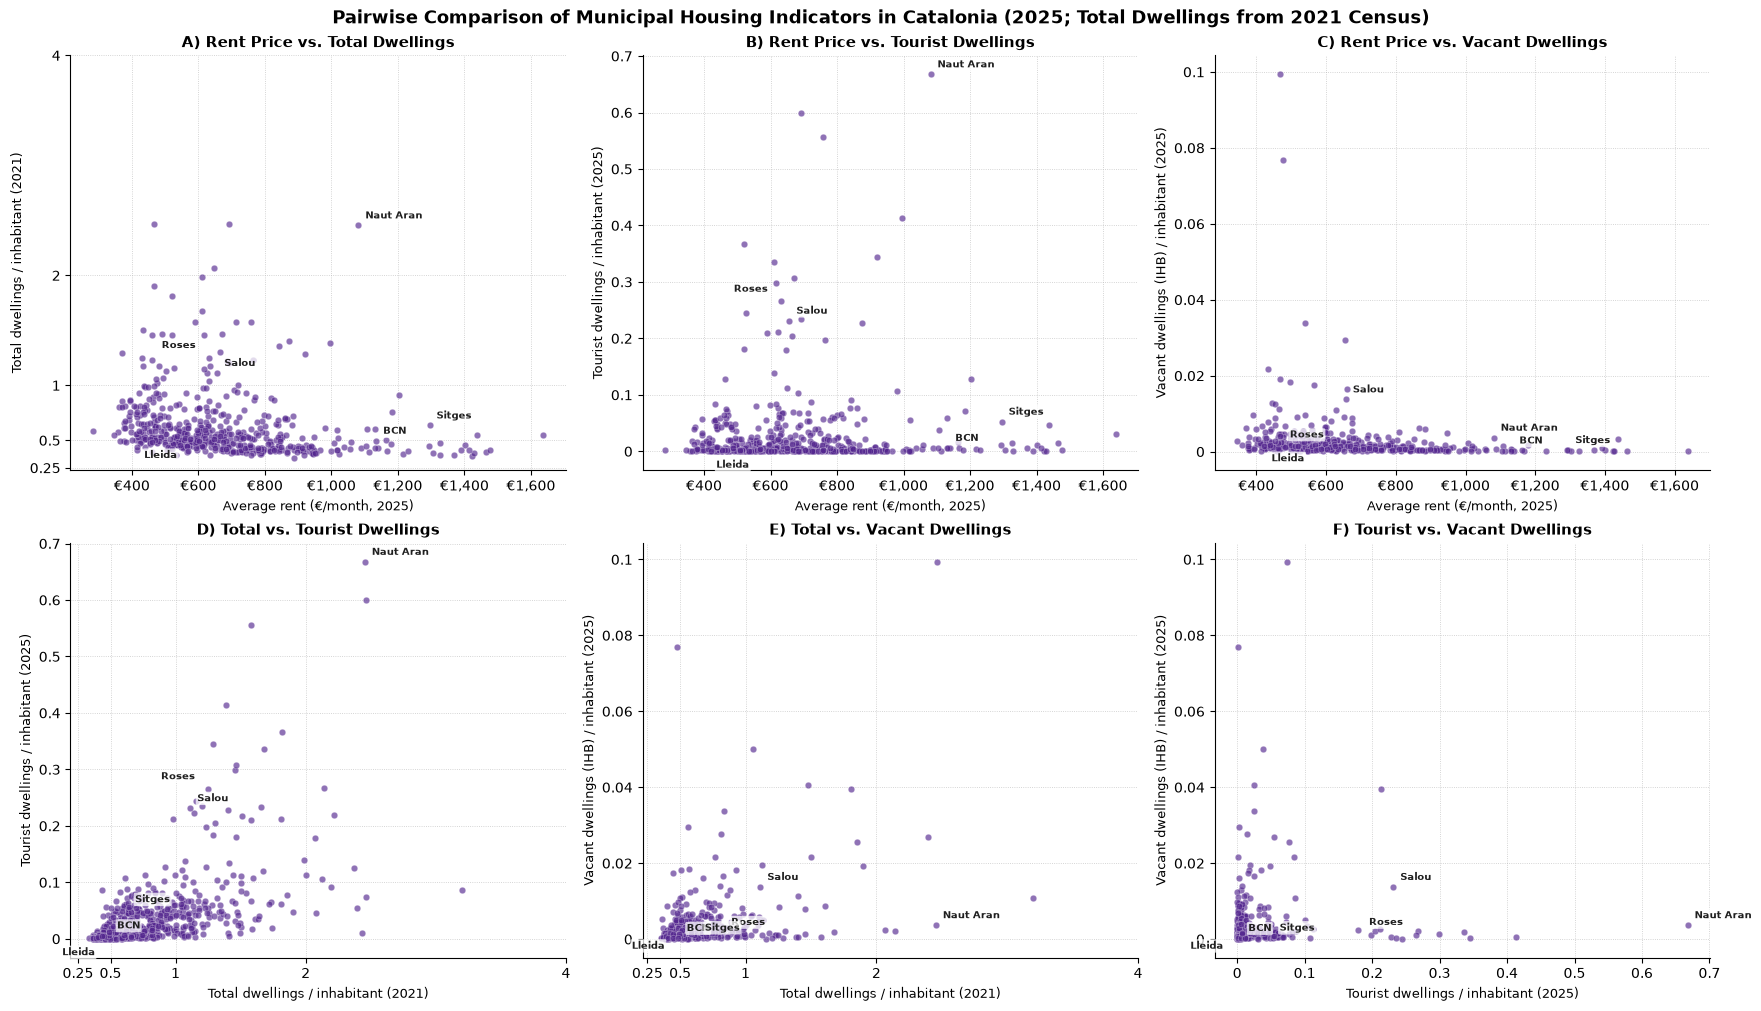

In [18]:
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

# 1. GEOGRAPHIC LAYER, POPULATION (2021 & 2025), AND TOTAL DWELLINGS (2021 CENSUS)
municipis = gpd.read_file("../Data/CatalunyaMapMunicipalities.json")  # Load municipal geographic layer of Catalonia
municipis["CODIMUNI"] = municipis["CODIMUNI"].astype(str).str.zfill(6)  # Convert municipal code to 6-digit zero-padded string

# 1A. Population 2021 
ruta_pob_2021 = "../Data/BuildingsAvailable/poblacio_codis.xlsx"
df_pob_hist = pd.read_excel(ruta_pob_2021, sheet_name="Dades", skiprows=1, dtype={0: str})
df_pob_hist = df_pob_hist.rename(columns={df_pob_hist.columns[0]: "Codi", df_pob_hist.columns[1]: "Any"})
df_pob_hist["Codi"] = df_pob_hist["Codi"].ffill().str.strip().str.zfill(6)
df_pob_hist = df_pob_hist[df_pob_hist["Codi"].str.match(r"^\d{6}$")].copy()
df_pob_hist["Any"] = df_pob_hist["Any"].astype(int)
df_pob_hist["Poblacio_2021"] = pd.to_numeric(df_pob_hist["Total"], errors="coerce")
pob_2021 = df_pob_hist[df_pob_hist["Any"] == 2021][["Codi", "Poblacio_2021"]]

# 1B. Population 2025 
ruta_pob_2025 = "../Data/Habitants.csv"
df_pob_2025 = pd.read_csv(ruta_pob_2025, dtype=str)
df_pob_2025 = df_pob_2025[(df_pob_2025["YEAR"] == "2025") & (df_pob_2025["SEX"] == "TOTAL")].copy()
df_pob_2025["Codi"] = df_pob_2025["MUN"].str.strip().str.zfill(6)
df_pob_2025["Poblacio_2025"] = pd.to_numeric(df_pob_2025["value"], errors="coerce")
pob_2025 = df_pob_2025[["Codi", "Poblacio_2025"]]

# 1C. Total family dwellings 
ruta_hab = "../Data/BuildingsAvailable/habitatges2021.csv"
df_hab = pd.read_csv(ruta_hab, sep=";", skiprows=5, dtype={"Codi": str})
df_hab = df_hab.dropna(subset=["Codi"]).copy()
df_hab["Codi"] = df_hab["Codi"].str.strip().str.zfill(6)
df_hab["Total"] = pd.to_numeric(df_hab["Total habitatges familiars"], errors="coerce")

# 2. RENT PRICE, TOURIST DWELLINGS, AND VACANT DWELLINGS (2025)
# 2A. Average monthly rent 
ruta_lloguer = "../Data/RentPrice/RentPrice.csv"
df_lloguer = pd.read_csv(ruta_lloguer, sep=";", dtype=str)
df_lloguer = df_lloguer[
    (df_lloguer["Àmbit territorial"] == "Municipi")
    & (df_lloguer["Any"] == "2025")
].copy()
if "gener-desembre" in df_lloguer["Període"].values:
    df_lloguer = df_lloguer[df_lloguer["Període"] == "gener-desembre"].copy()

df_lloguer["Codi5"] = df_lloguer["Codi territorial"].str.strip().str.zfill(5)
df_lloguer["Lloguer"] = pd.to_numeric(
    df_lloguer["Renda"].str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
    errors="coerce",
)
df_lloguer_2025 = df_lloguer.groupby("Codi5", as_index=False)["Lloguer"].mean()

# 2B. Tourist-use dwellings 
ruta_tur = "../Data/TouristicRentals/prova2025.csv"
df_tur = pd.read_csv(ruta_tur, dtype=str)
df_hut = df_tur[df_tur["tipus_establiment"] == "Habitatges d'ús turístic"].copy()
df_hut["Codi"] = df_hut["codi_municipi_idescat"].str.strip().str.zfill(6)
tur_per_muni = df_hut.groupby("Codi").size().reset_index(name="Num_turistics")

# 2C. Vacant dwellings 
ruta_buits = "../Data/EmptyBuildings/EmptyBuildings.csv"
df_ihb = pd.read_csv(ruta_buits, dtype=str)
df_ihb_2025 = df_ihb[df_ihb["Any"] == "2025"].copy()
df_ihb_2025["Codi"] = df_ihb_2025["Codi"].str.strip().str.zfill(6)
df_ihb_2025["Habitatges"] = pd.to_numeric(df_ihb_2025["Habitatges"].str.replace(".", "", regex=False), errors="coerce")
buits_per_muni = df_ihb_2025.groupby("Codi")["Habitatges"].sum().reset_index(name="Num_buits")

# 3. MERGE ALL VARIABLES AND NORMALIZE PER INHABITANT (WITHOUT ZERO-FILLING)
df_base = (
    df_hab[["Codi", "Total"]]
    .merge(pob_2021, on="Codi", how="inner")
    .merge(pob_2025, on="Codi", how="inner")
    .merge(municipis[["CODIMUNI", "NOMMUNI"]], left_on="Codi", right_on="CODIMUNI", how="inner")
    .merge(tur_per_muni, on="Codi", how="left")
    .merge(buits_per_muni, on="Codi", how="left")
)
df_base = df_base.dropna(subset=["Total", "Poblacio_2021", "Poblacio_2025"]).copy()
df_base = df_base[(df_base["Poblacio_2021"] > 0) & (df_base["Poblacio_2025"] > 0) & (df_base["Total"] > 0)].copy()

# Compute per-capita ratios (2021 dwellings / 2021 pop; 2025 tourist & vacant dwellings / 2025 pop)
df_base["Hab_per_hab"] = df_base["Total"] / df_base["Poblacio_2021"]
df_base["Tur_per_hab"] = df_base["Num_turistics"] / df_base["Poblacio_2025"]
df_base["Buits_per_hab"] = df_base["Num_buits"] / df_base["Poblacio_2025"]

# Merge 2025 average rent price
df_base["Codi5"] = df_base["Codi"].str[:5]
df = df_base.merge(df_lloguer_2025[["Codi5", "Lloguer"]], on="Codi5", how="left")

# 4. GENERATE THE 6 SUBPLOTS IN A 2x3 GRID (ONLY VALUES > 0)
fig, axes = plt.subplots(2, 3, figsize=(17.5, 10), layout="constrained")
axes = axes.flatten()

# Pair configuration: (col_x, col_y, label_x, label_y, title, scale_x, scale_y)
parelles = [
    ("Lloguer", "Hab_per_hab", "Average rent (€/month, 2025)", "Total dwellings / inhabitant (2021)", "A) Rent Price vs. Total Dwellings", "linear", "log"),
    ("Lloguer", "Tur_per_hab", "Average rent (€/month, 2025)", "Tourist dwellings / inhabitant (2025)", "B) Rent Price vs. Tourist Dwellings", "linear", "log"),
    ("Lloguer", "Buits_per_hab", "Average rent (€/month, 2025)", "Vacant dwellings (IHB) / inhabitant (2025)", "C) Rent Price vs. Vacant Dwellings", "linear", "log"),
    ("Hab_per_hab", "Tur_per_hab", "Total dwellings / inhabitant (2021)", "Tourist dwellings / inhabitant (2025)", "D) Total vs. Tourist Dwellings", "log", "log"),
    ("Hab_per_hab", "Buits_per_hab", "Total dwellings / inhabitant (2021)", "Vacant dwellings (IHB) / inhabitant (2025)", "E) Total vs. Vacant Dwellings", "log", "log"),
    ("Tur_per_hab", "Buits_per_hab", "Tourist dwellings / inhabitant (2025)", "Vacant dwellings (IHB) / inhabitant (2025)", "F) Tourist vs. Vacant Dwellings", "log", "log"),
]

# Key reference municipalities to annotate in each subplot: (regex_pattern, short_label, dx, dy)
municipis_ref = [
    (r"^Barcelona$", "BCN", 5, 5),
    (r"^Salou$", "Salou", 5, 5),
    (r"^Roses$", "Roses", -34, 7),
    (r"^Naut Aran$", "Naut Aran", 5, 5),
    (r"^Lleida$", "Lleida", -34, -12),
    (r"^Sitges$", "Sitges", 5, 5),
]

fmt_euros = ticker.FuncFormatter(lambda x, _: f"€{int(x):,}")
fmt_decimal = ticker.FuncFormatter(lambda x, _: f"{x:g}")

for ax, (col_x, col_y, lbl_x, lbl_y, titol, esc_x, esc_y) in zip(axes, parelles):
    # Drop rows with missing (NaN) or zero values on either axis
    sub = df.dropna(subset=[col_x, col_y]).copy()
    sub = sub[(sub[col_x] > 0) & (sub[col_y] > 0)].copy()

    ax.scatter(
        sub[col_x],
        sub[col_y],
        color="#54278f",
        s=22,
        alpha=0.65,
        edgecolors="white",
        linewidth=0.25,
        zorder=3,
    )

    # Configure X-axis scale and formatting
    if esc_x == "log":
        if col_x == "Hab_per_hab":
            ax.set_xticks([0.25, 0.5, 1, 2, 4])
        ax.xaxis.set_major_formatter(fmt_decimal)
        ax.xaxis.set_minor_formatter(ticker.NullFormatter())
    else:
        ax.xaxis.set_major_formatter(fmt_euros)

    # Configure Y-axis scale and formatting
    if esc_y == "log":
        if col_y == "Hab_per_hab":
            ax.set_yticks([0.25, 0.5, 1, 2, 4])
        ax.yaxis.set_major_formatter(fmt_decimal)
        ax.yaxis.set_minor_formatter(ticker.NullFormatter())
    else:
        ax.yaxis.set_major_formatter(fmt_euros)

    # Annotate reference municipalities with a subtle white background box for readability
    for patro, nom_curt, dx, dy in municipis_ref:
        fila = sub[sub["NOMMUNI"].str.contains(patro, case=False, regex=True)]
        if not fila.empty:
            r = fila.iloc[0]
            ax.annotate(
                nom_curt,
                xy=(r[col_x], r[col_y]),
                xytext=(dx, dy),
                textcoords="offset points",
                fontsize=7.2,
                fontweight="bold",
                color="#1f1f1f",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.75),
                zorder=4,
            )

    ax.grid(True, which="major", linestyle=":", linewidth=0.6, alpha=0.7, zorder=1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlabel(lbl_x, fontsize=9.5)
    ax.set_ylabel(lbl_y, fontsize=9.5)
    ax.set_title(titol, fontweight="bold", fontsize=10.5)

fig.suptitle(
    "Pairwise Comparison of Municipal Housing Indicators in Catalonia (2025; Total Dwellings from 2021 Census)",
    fontweight="bold",
    fontsize=13,
)
plt.show()